# ML Part: HOG + SVM / KNN / Random Forest
Member: Mugheeza

Steps: 1) download data, 2) explore, 3) preprocess + split, 4) HOG features, 5) train models, 6) evaluate.

**Run the cells from top to bottom.**

## 1. Install and load the dataset

In [1]:
!pip install -q kagglehub

In [2]:
import os, cv2, numpy as np, matplotlib.pyplot as plt
import kagglehub

# Downloads FER-2013 (train/test folders, one sub-folder per emotion)
path = kagglehub.dataset_download("msambare/fer2013")
print("Downloaded to:", path)

root = None
for dirpath, dirnames, _ in os.walk(path):
    if "train" in dirnames and "test" in dirnames:
        root = dirpath
        break
train_dir, test_dir = os.path.join(root, "train"), os.path.join(root, "test")
classes = sorted(os.listdir(train_dir))
print("Classes:", classes)

def load_split(folder):
    X, y = [], []
    for idx, cls in enumerate(classes):
        cls_dir = os.path.join(folder, cls)
        for name in os.listdir(cls_dir):
            img = cv2.imread(os.path.join(cls_dir, name), 0)       # grayscale
            if img is None:
                continue
            if img.shape != (48, 48):
                img = cv2.resize(img, (48, 48))
            X.append(img)
            y.append(idx)
    return np.array(X), np.array(y)

X_train_all, y_train_all = load_split(train_dir)
X_test, y_test = load_split(test_dir)
print("Train:", X_train_all.shape, " Test:", X_test.shape)

100%|██████████| 60.3M/60.3M [00:00<00:00, 89.1MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/msambare/fer2013/versions/1
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Train: (28709, 48, 48)  Test: (7178, 48, 48)


## 2. Explore the data
Note for the report: the Disgust class has far fewer images than the others (class imbalance).

angry       3995
disgust      436
fear        4097
happy       7215
neutral     4965
sad         4830
surprise    3171
Name: count, dtype: int64


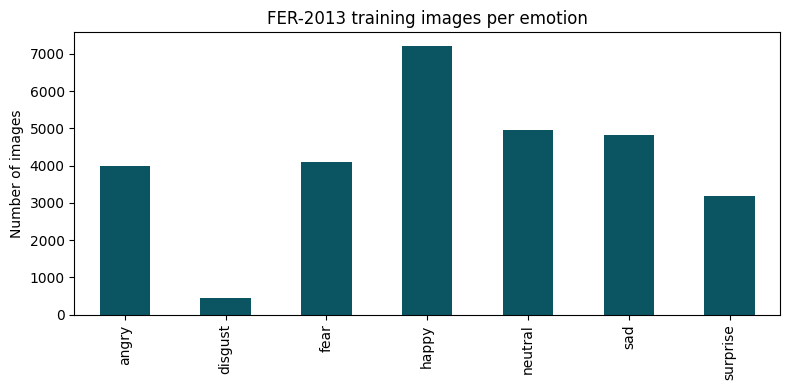

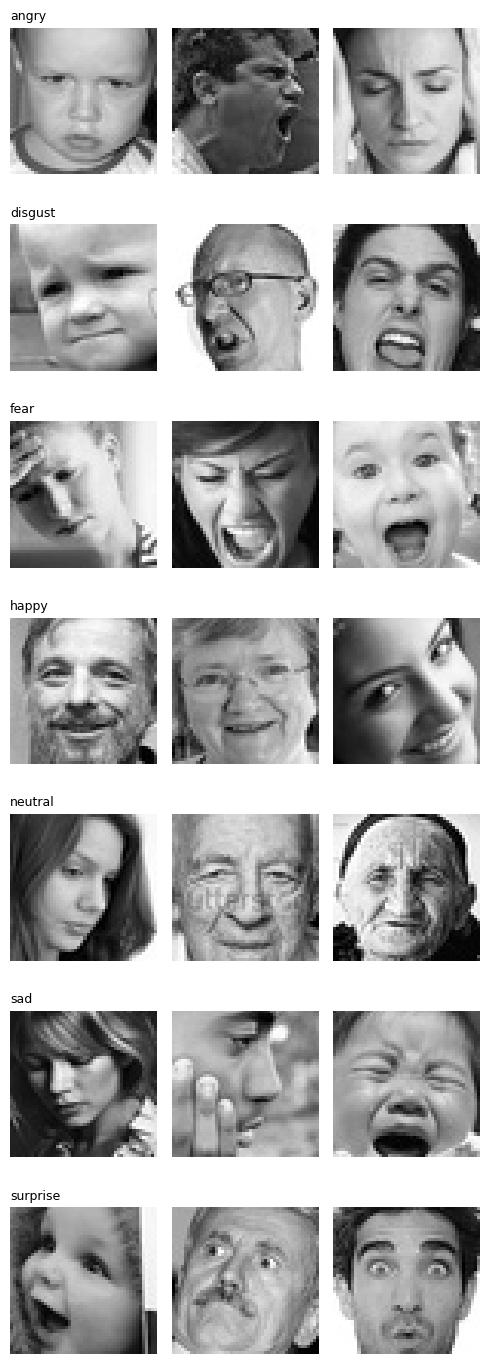

In [3]:
import pandas as pd

counts = pd.Series(y_train_all).map(lambda i: classes[i]).value_counts().reindex(classes)
print(counts)

plt.figure(figsize=(8, 4))
counts.plot(kind="bar", color="#0B5563")
plt.title("FER-2013 training images per emotion")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

# 3 sample images per emotion
fig, axes = plt.subplots(len(classes), 3, figsize=(5, 2 * len(classes)))
for r, cls_idx in enumerate(range(len(classes))):
    ids = np.where(y_train_all == cls_idx)[0][:3]
    for c, i in enumerate(ids):
        axes[r, c].imshow(X_train_all[i], cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(classes[cls_idx], fontsize=9, loc="left")
plt.tight_layout()
plt.show()

## 3. Preprocessing and train/validation/test split
Pixels are scaled to 0-1. Labels are already numbers (0-6, in the order printed above).

In [4]:
from sklearn.model_selection import train_test_split

# Same split for everyone in the group: random_state=42, 15% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all, test_size=0.15, stratify=y_train_all, random_state=42
)
print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

# scale pixels to 0-1
X_train = X_train.astype("float32") / 255.0
X_val   = X_val.astype("float32") / 255.0
X_test_n = X_test.astype("float32") / 255.0

Train: (24402, 48, 48) Validation: (4307, 48, 48) Test: (7178, 48, 48)


## 4. HOG feature extraction
HOG turns each 48x48 image into a feature vector (edges and shapes).

In [5]:
from skimage.feature import hog
from tqdm.auto import tqdm

def extract_hog(images):
    feats = [
        hog(img, orientations=9, pixels_per_cell=(6, 6), cells_per_block=(2, 2))
        for img in tqdm(images)
    ]
    return np.array(feats)

H_train = extract_hog(X_train)
H_val   = extract_hog(X_val)
H_test  = extract_hog(X_test_n)
print("HOG feature size per image:", H_train.shape[1])

  0%|          | 0/24402 [00:00<?, ?it/s]

  0%|          | 0/4307 [00:00<?, ?it/s]

  0%|          | 0/7178 [00:00<?, ?it/s]

HOG feature size per image: 1764


## 5. Evaluation helper

In [6]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)
import time

results = []

def evaluate(model, name, Xtr, ytr):
    t0 = time.time()
    model.fit(Xtr, ytr)
    train_time = time.time() - t0

    pred = model.predict(H_test)
    acc = accuracy_score(y_test, pred)
    results.append({
        "Model": name,
        "Test accuracy": round(acc, 4),
        "Precision (macro)": round(precision_score(y_test, pred, average="macro", zero_division=0), 4),
        "Recall (macro)": round(recall_score(y_test, pred, average="macro", zero_division=0), 4),
        "F1 (macro)": round(f1_score(y_test, pred, average="macro", zero_division=0), 4),
        "Train time (s)": round(train_time, 1),
    })
    print(name, "- test accuracy:", round(acc, 4), "- time:", round(train_time, 1), "s")
    print(classification_report(y_test, pred, target_names=classes, zero_division=0))

    fig, ax = plt.subplots(figsize=(6, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=classes, xticks_rotation=45, ax=ax, colorbar=False
    )
    ax.set_title("Confusion matrix: " + name)
    plt.tight_layout()
    plt.show()

## 6. Baseline model: HOG + SVM
SVM can be slow on all 24k images, so by default it trains on a subset of 8000. Set `USE_SUBSET = False` to use everything (can take 10-20 minutes).

HOG + SVM - test accuracy: 0.4784 - time: 150.7 s
              precision    recall  f1-score   support

       angry       0.36      0.36      0.36       958
     disgust       0.96      0.22      0.35       111
        fear       0.34      0.30      0.32      1024
       happy       0.61      0.73      0.67      1774
     neutral       0.43      0.44      0.43      1233
         sad       0.37      0.37      0.37      1247
    surprise       0.69      0.55      0.61       831

    accuracy                           0.48      7178
   macro avg       0.54      0.42      0.45      7178
weighted avg       0.48      0.48      0.47      7178



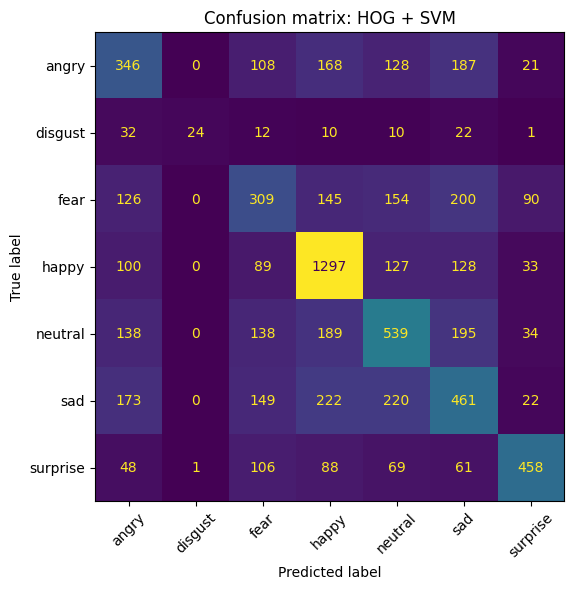

In [7]:
from sklearn.svm import SVC

USE_SUBSET = True
N = 8000 if USE_SUBSET else len(H_train)

svm = SVC(kernel="rbf", C=10, gamma="scale")
evaluate(svm, "HOG + SVM", H_train[:N], y_train[:N])

## 7. KNN and Random Forest

HOG + KNN - test accuracy: 0.4606 - time: 0.0 s
              precision    recall  f1-score   support

       angry       0.36      0.38      0.37       958
     disgust       0.34      0.34      0.34       111
        fear       0.39      0.31      0.34      1024
       happy       0.51      0.77      0.61      1774
     neutral       0.41      0.43      0.42      1233
         sad       0.45      0.23      0.31      1247
    surprise       0.66      0.49      0.57       831

    accuracy                           0.46      7178
   macro avg       0.44      0.42      0.42      7178
weighted avg       0.46      0.46      0.44      7178



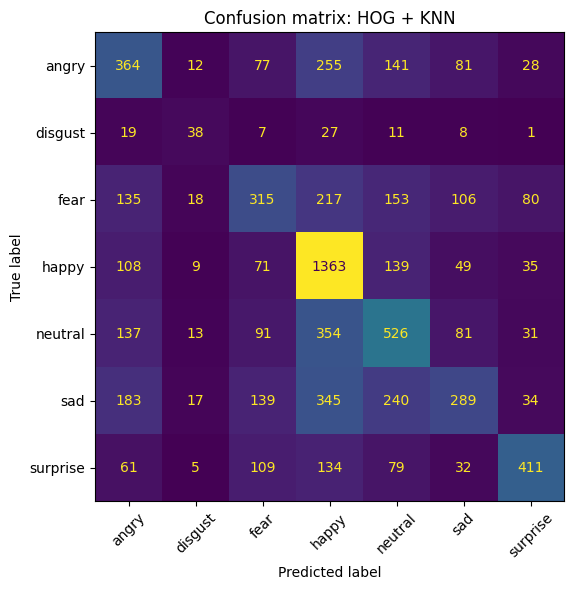

HOG + Random Forest - test accuracy: 0.4508 - time: 277.9 s
              precision    recall  f1-score   support

       angry       0.46      0.17      0.25       958
     disgust       1.00      0.26      0.41       111
        fear       0.46      0.22      0.30      1024
       happy       0.44      0.87      0.58      1774
     neutral       0.41      0.43      0.42      1233
         sad       0.35      0.29      0.31      1247
    surprise       0.80      0.47      0.59       831

    accuracy                           0.45      7178
   macro avg       0.56      0.39      0.41      7178
weighted avg       0.48      0.45      0.42      7178



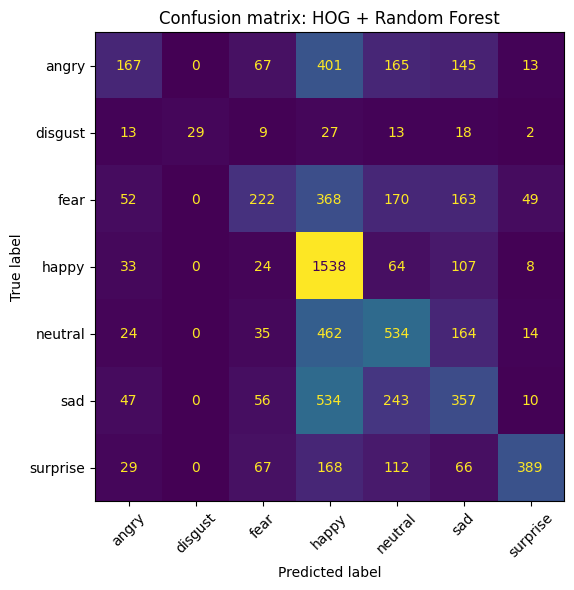

In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

evaluate(KNeighborsClassifier(n_neighbors=5, n_jobs=-1), "HOG + KNN", H_train, y_train)
evaluate(RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42), "HOG + Random Forest", H_train, y_train)

## 8. Results table (for report)

In [9]:
import pandas as pd
results_df = pd.DataFrame(results)
display(results_df)
results_df.to_csv("ml_results.csv", index=False)

from google.colab import files
files.download("ml_results.csv")

,Model,Test accuracy,Precision (macro),Recall (macro),F1 (macro),Train time (s)
0,HOG + SVM,0.4784,0.5379,0.4240,0.4453,150.7
1,HOG + KNN,0.4606,0.4449,0.4216,0.4220,0.0
2,HOG + Random Forest,0.4508,0.5603,0.3867,0.4104,277.9


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>